# Demand Forecasting for Supply Chain Optimization Using Historical Sales Data

**Course:** Predictive Analytics

**Objective:** To analyze historical retail sales data and develop a predictive model to forecast future sales, supporting better supply chain planning and inventory management.

## 1. Problem Statement and Objective

Retail businesses need accurate sales forecasts to plan inventory, manage stock levels, and reduce the risk of overstocking or stockouts.

The objective of this project is to analyze historical sales data, identify sales patterns, and develop a predictive model for forecasting sales.

In [1]:

import pandas as pd

train = pd.read_csv('/content/train.csv')
stores = pd.read_csv('/content/stores.csv')
holidays = pd.read_csv('/content/holidays_events.csv')
oil = pd.read_csv('/content/oil.csv')
transactions = pd.read_csv('/content/transactions.csv')
test = pd.read_csv('/content/test.csv')

print("Train dataset:", train.shape)
print("Stores dataset:", stores.shape)
print("Holidays dataset:", holidays.shape)
print("Oil dataset:", oil.shape)
print("Transactions dataset:", transactions.shape)
print("Test dataset:", test.shape)

print("\nFirst 5 rows of training data:")
display(train.head())


Train dataset: (3000888, 6)
Stores dataset: (54, 5)
Holidays dataset: (350, 6)
Oil dataset: (1218, 2)
Transactions dataset: (83488, 3)
Test dataset: (28512, 5)

First 5 rows of training data:


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 2. Dataset Loading and Understanding

The project uses the Store Sales – Time Series Forecasting dataset from Kaggle. It contains historical sales records, store information, holidays, oil prices, and transaction data.

The datasets are loaded using Pandas for inspection and analysis.

In [2]:

# 1. Understand the dataset
print("Dataset Information:")
train.info()

# 2. Check missing values
print("\nMissing Values:")
print(train.isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate Rows:", train.duplicated().sum())

# 4. Check summary statistics
print("\nSummary Statistics:")
display(train.describe())

# 5. Check unique values
print("\nNumber of Stores:", train['store_nbr'].nunique())
print("Product Families:", train['family'].nunique())
print("Date Range:", train['date'].min(), "to", train['date'].max())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB

Missing Values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate Rows: 0

Summary Statistics:


,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02



Number of Stores: 54
Product Families: 33
Date Range: 2013-01-01 to 2017-08-15


## 3. Data Understanding and Quality Assessment

This stage examines the structure of the training dataset, its columns, data types, missing values, duplicate records, and summary statistics.

The purpose is to understand the data quality and identify any preprocessing requirements before model development.

## 4. Data Preprocessing and Feature Engineering

The date column is converted into a datetime format. New features such as year, month, day, and day of the week are extracted to help identify time-based sales patterns.

In [3]:

# Convert date column to datetime
train['date'] = pd.to_datetime(train['date'])

# Create time-based features
train['year'] = train['date'].dt.year
train['month'] = train['date'].dt.month
train['day'] = train['date'].dt.day
train['day_of_week'] = train['date'].dt.dayofweek

# Check the updated dataset
print("Updated dataset shape:", train.shape)
print("\nNew columns:")
print(train.columns.tolist())

print("\nSample data:")
display(train.head())


Updated dataset shape: (3000888, 10)

New columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'year', 'month', 'day', 'day_of_week']

Sample data:


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,1
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,1
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,1
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,1


5. Exploratory Data Analysis (EDA)

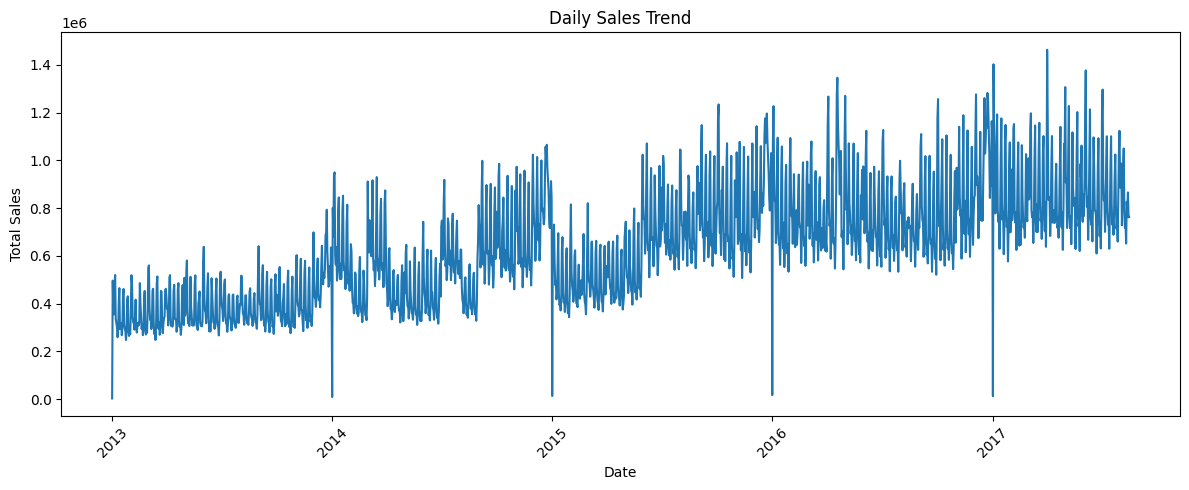

In [4]:
# Analyze overall sales patterns
daily_sales = train.groupby('date')['sales'].sum()

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

5.1 Sales Distribution by Product Family

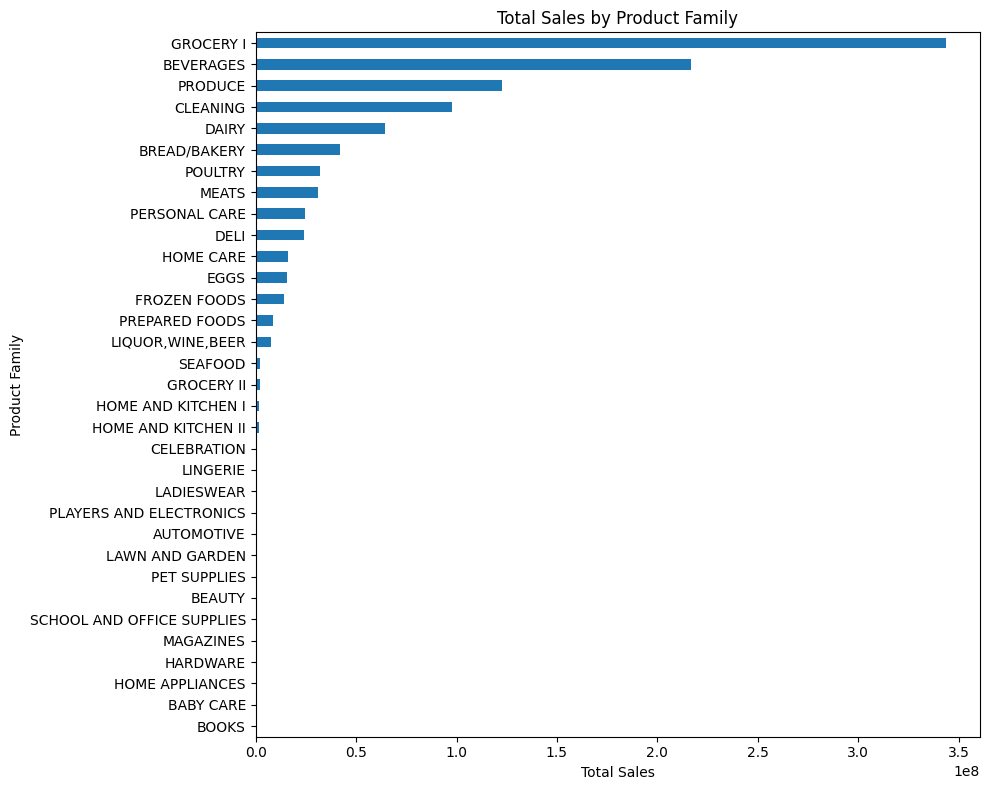

In [5]:
family_sales = train.groupby('family')['sales'].sum().sort_values()

plt.figure(figsize=(10, 8))
family_sales.plot(kind='barh')
plt.title('Total Sales by Product Family')
plt.xlabel('Total Sales')
plt.ylabel('Product Family')
plt.tight_layout()
plt.show()

5.2 Monthly Sales Trend

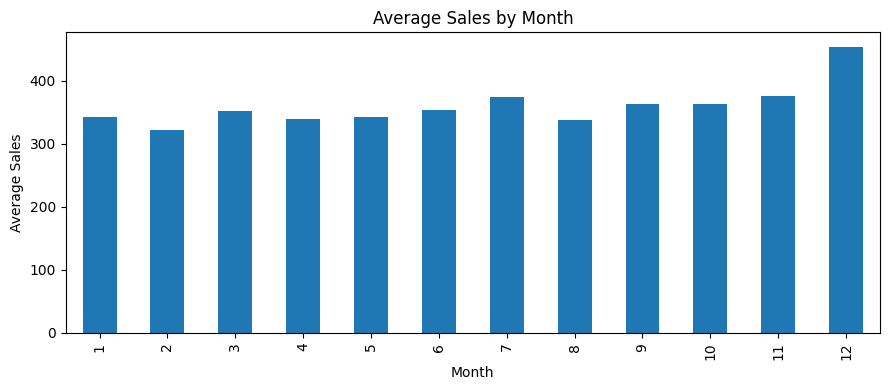

In [6]:

monthly_sales = train.groupby('month')['sales'].mean()

plt.figure(figsize=(9, 4))
monthly_sales.plot(kind='bar')
plt.title('Average Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.tight_layout()
plt.show()


6. Multi-Dataset Integration and Preprocessing

In [7]:

# Prepare supporting datasets
stores['store_nbr'] = stores['store_nbr'].astype(int)
oil['date'] = pd.to_datetime(oil['date'])
holidays['date'] = pd.to_datetime(holidays['date'])

# Create one holiday indicator per date
holiday_dates = holidays.groupby('date').size().reset_index(name='holiday_count')
holiday_dates['is_holiday'] = 1

# Merge store information with sales
train_enriched = train.merge(stores, on='store_nbr', how='left')
train_enriched = train_enriched.merge(oil, on='date', how='left')
train_enriched = train_enriched.merge(
    holiday_dates[['date', 'is_holiday']], on='date', how='left'
)
train_enriched['is_holiday'] = train_enriched['is_holiday'].fillna(0)

print("Integrated dataset shape:", train_enriched.shape)
display(train_enriched.head())


Integrated dataset shape: (3000888, 16)


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,city,state,type,cluster,dcoilwtico,is_holiday
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,Quito,Pichincha,D,13,NaN,1.0
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,1,Quito,Pichincha,D,13,NaN,1.0
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,1,Quito,Pichincha,D,13,NaN,1.0
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,1,Quito,Pichincha,D,13,NaN,1.0
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,1,Quito,Pichincha,D,13,NaN,1.0


7. Predictive Model Development

In [8]:

# Aggregate sales across stores and product families by date
daily = train_enriched.groupby('date').agg(
    sales=('sales', 'sum'),
    promotion=('onpromotion', 'sum'),
    oil_price=('dcoilwtico', 'mean'),
    is_holiday=('is_holiday', 'max')
).reset_index()

daily['oil_price'] = daily['oil_price'].ffill().bfill()
daily['year'] = daily['date'].dt.year
daily['month'] = daily['date'].dt.month
daily['day'] = daily['date'].dt.day
daily['day_of_week'] = daily['date'].dt.dayofweek

# Create past-sales features
daily = daily.sort_values('date')
daily['lag_7'] = daily['sales'].shift(7)
daily['lag_14'] = daily['sales'].shift(14)
daily = daily.dropna().reset_index(drop=True)

print("Model dataset shape:", daily.shape)
display(daily.head())


Model dataset shape: (1670, 11)


,date,sales,promotion,oil_price,is_holiday,year,month,day,day_of_week,lag_7,lag_14
0,2013-01-15,299129.549954,0,93.26,0.0,2013,1,15,1,318347.777981,2511.618999
1,2013-01-16,318347.913946,0,94.28,0.0,2013,1,16,2,302530.809018,496092.417944
2,2013-01-17,267498.515975,0,95.49,0.0,2013,1,17,3,258982.003049,361461.231124
3,2013-01-18,296130.850028,0,95.61,0.0,2013,1,18,4,289737.685085,354459.677093
4,2013-01-19,432459.852021,0,95.61,0.0,2013,1,19,5,403258.212011,477350.121229


8. Model Training and Evaluation

In [10]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

features = [
    'promotion', 'oil_price', 'is_holiday',
    'year', 'month', 'day', 'day_of_week', 'lag_7', 'lag_14'
]

# Time-based split: earlier dates for training, later dates for testing
split = int(len(daily) * 0.8)
train_data = daily.iloc[:split]
test_data = daily.iloc[split:]

model = RandomForestRegressor(
    n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
)
model.fit(train_data[features], train_data['sales'])

predictions = model.predict(test_data[features])

mae = mean_absolute_error(test_data['sales'], predictions)
rmse = np.sqrt(mean_squared_error(test_data['sales'], predictions))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))


MAE: 78460.9
RMSE: 119450.47


9. Results and Interpretation

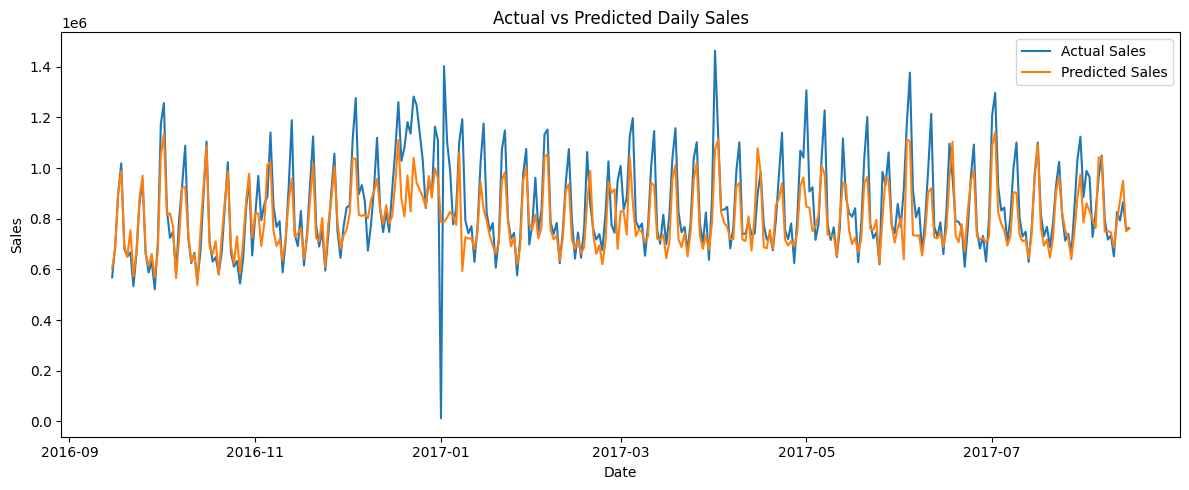

In [11]:

plt.figure(figsize=(12, 5))
plt.plot(test_data['date'], test_data['sales'], label='Actual Sales')
plt.plot(test_data['date'], predictions, label='Predicted Sales')
plt.title('Actual vs Predicted Daily Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.tight_layout()
plt.show()


10. Feature Importance Analysis

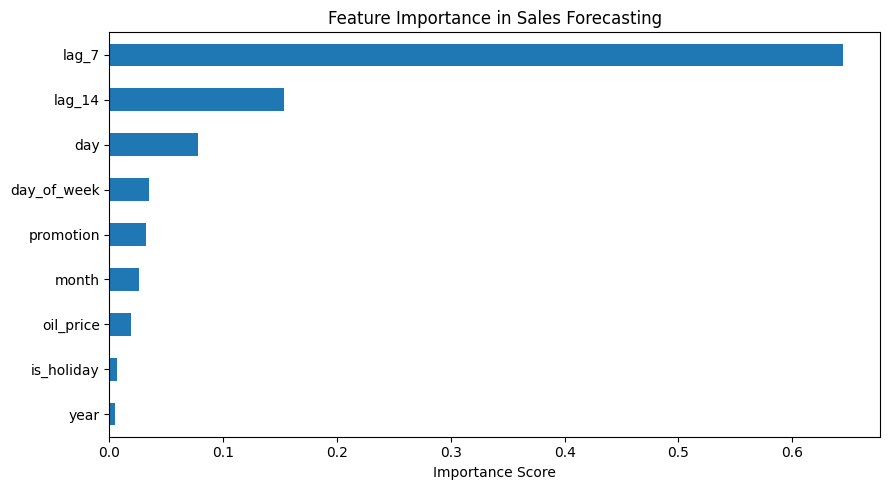

In [12]:
importance = pd.Series(
    model.feature_importances_, index=features
).sort_values()

importance.plot(kind='barh', figsize=(9, 5))
plt.title('Feature Importance in Sales Forecasting')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

11. Model Validation and Baseline Comparison

In [13]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Baseline: predict sales using sales from 7 days earlier
baseline_predictions = test_data['lag_7']

baseline_mae = mean_absolute_error(
    test_data['sales'], baseline_predictions
)
baseline_rmse = np.sqrt(mean_squared_error(
    test_data['sales'], baseline_predictions
))

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))
print("Random Forest MAE:", round(mae, 2))
print("Random Forest RMSE:", round(rmse, 2))


Baseline MAE: 108539.92
Baseline RMSE: 170606.81
Random Forest MAE: 78460.9
Random Forest RMSE: 119450.47


### 12. Time-Series Lag Feature Validation

This step verifies that the lag features use historical sales values from previous days rather than future sales information.

In [14]:
check = daily[['date', 'sales', 'lag_7', 'lag_14']].copy()

check['actual_sales_7_days_earlier'] = check['sales'].shift(7)
check['actual_sales_14_days_earlier'] = check['sales'].shift(14)

display(check.tail(10))

,date,sales,lag_7,lag_14,actual_sales_7_days_earlier,actual_sales_14_days_earlier
1660,2017-08-06,1.049559e+06,1.123752e+06,1.024289e+06,1.123752e+06,1.024289e+06
1661,2017-08-07,7.974650e+05,8.858568e+05,8.165643e+05,8.858568e+05,8.165643e+05
1662,2017-08-08,7.177663e+05,9.885278e+05,7.135816e+05,9.885278e+05,7.135816e+05
1663,2017-08-09,7.341397e+05,9.647120e+05,7.406530e+05,9.647120e+05,7.406530e+05
1664,2017-08-10,6.513869e+05,7.280685e+05,6.598498e+05,7.280685e+05,6.598498e+05
1665,2017-08-11,8.263737e+05,8.277757e+05,8.350997e+05,8.277757e+05,8.350997e+05
1666,2017-08-12,7.926305e+05,9.656937e+05,1.032311e+06,9.656937e+05,1.032311e+06
1667,2017-08-13,8.656397e+05,1.049559e+06,1.123752e+06,1.049559e+06,1.123752e+06
1668,2017-08-14,7.609224e+05,7.974650e+05,8.858568e+05,7.974650e+05,8.858568e+05
1669,2017-08-15,7.626619e+05,7.177663e+05,9.885278e+05,7.177663e+05,9.885278e+05


## 13. Interpretation and Supply Chain Applications

The model's MAE and RMSE measure the difference between actual and predicted daily sales. Lower values indicate more accurate predictions. Comparing the Random Forest model with the baseline helps determine whether machine learning improves forecasting performance.

Feature importance analysis identified sales from seven days earlier as the most influential feature. These forecasts could help retailers anticipate demand, plan inventory replenishment, and prepare for changes in sales. However, actual inventory savings have not been measured in this project.

The model predicts total daily sales across the available stores and product families, rather than individual product demand. Therefore, further development would be needed for detailed store-level inventory decisions.**bold text**

## 14. Conclusion

This project demonstrated the use of Predictive Analytics to forecast daily retail sales using historical sales data. Multiple datasets containing store details, holidays, and oil prices were integrated to improve the analysis. Data preprocessing and feature engineering were performed, followed by training a Random Forest Regression model.

The model achieved a Mean Absolute Error (**MAE) of 78,460.90** and a **Root Mean Squared Error (RMSE) of 119,450.47**. Feature importance analysis showed that sales from the previous seven days was the most influential predictor. The results demonstrate how historical sales patterns can support demand forecasting and better supply chain planning.

Future improvements could include testing additional forecasting algorithms and developing store-level and product-level predictions.